In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import scipy
import sklearn

print("Environment setup successful!")
print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)
print("SciPy:", scipy.__version__)
print("Scikit-learn:", sklearn.__version__)

Environment setup successful!
Pandas: 3.1.1
NumPy: 2.5.4
SciPy: 1.18.1
Scikit-learn: 1.9.1


In [1]:
import pandas as pd

# Load the retail dataset
df = pd.read_csv("../Data/Raw/retail_demand.csv")

# Display basic dataset information
print("Dataset loaded successfully!")
print("Rows and columns:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nFirst 5 records:")
display(df.head())

Dataset loaded successfully!
Rows and columns: (76000, 16)

Column names:
['Date', 'Store ID', 'Product ID', 'Category', 'Region', 'Inventory Level', 'Units Sold', 'Units Ordered', 'Price', 'Discount', 'Weather Condition', 'Promotion', 'Competitor Pricing', 'Seasonality', 'Epidemic', 'Demand']

First 5 records:


,Date,Store ID,Product ID,Category,Region,Inventory Level,Units Sold,Units Ordered,Price,Discount,Weather Condition,Promotion,Competitor Pricing,Seasonality,Epidemic,Demand
0,2022-01-01,S001,P0001,Electronics,North,195,102,252,72.72,5,Snowy,0,85.73,Winter,0,115
1,2022-01-01,S001,P0002,Clothing,North,117,117,249,80.16,15,Snowy,1,92.02,Winter,0,229
2,2022-01-01,S001,P0003,Clothing,North,247,114,612,62.94,10,Snowy,1,60.08,Winter,0,157
3,2022-01-01,S001,P0004,Electronics,North,139,45,102,87.63,10,Snowy,0,85.19,Winter,0,52
4,2022-01-01,S001,P0005,Groceries,North,152,65,271,54.41,0,Snowy,0,51.63,Winter,0,59


In [2]:
# Check missing values
print("Missing values in each column:")
print(df.isnull().sum())

# Check duplicate records
print("\nDuplicate rows:", df.duplicated().sum())

# Check data types
print("\nColumn data types:")
print(df.dtypes)

Missing values in each column:
Date                  0
Store ID              0
Product ID            0
Category              0
Region                0
Inventory Level       0
Units Sold            0
Units Ordered         0
Price                 0
Discount              0
Weather Condition     0
Promotion             0
Competitor Pricing    0
Seasonality           0
Epidemic              0
Demand                0
dtype: int64

Duplicate rows: 0

Column data types:
Date                      str
Store ID                  str
Product ID                str
Category                  str
Region                    str
Inventory Level         int64
Units Sold              int64
Units Ordered           int64
Price                 float64
Discount                int64
Weather Condition         str
Promotion               int64
Competitor Pricing    float64
Seasonality               str
Epidemic                int64
Demand                  int64
dtype: object


In [3]:
# Summary statistics for numerical columns
display(df.describe().round(2))

,Inventory Level,Units Sold,Units Ordered,Price,Discount,Promotion,Competitor Pricing,Epidemic,Demand
count,76000.00,76000.00,76000.00,76000.00,76000.00,76000.00,76000.00,76000.0,76000.00
mean,301.06,88.83,89.09,67.73,9.09,0.33,69.45,0.2,104.32
std,226.51,43.99,162.40,39.38,7.48,0.47,40.94,0.4,46.96
min,0.00,0.00,0.00,4.74,0.00,0.00,4.29,0.0,4.00
25%,136.00,58.00,0.00,32.00,5.00,0.00,32.62,0.0,71.00
50%,227.00,84.00,0.00,64.50,10.00,0.00,65.70,0.0,100.00
75%,408.00,114.00,121.00,95.83,10.00,1.00,97.93,0.0,133.00
max,2267.00,426.00,1616.00,228.03,25.00,1.00,261.22,1.0,430.00


In [4]:
# Compare units sold and demand
print("Units Sold statistics:")
print(df["Units Sold"].describe())

print("\nDemand statistics:")
print(df["Demand"].describe())

print("\nCorrelation between Units Sold and Demand:")
print(df[["Units Sold", "Demand"]].corr().round(3))

print("\nSample comparison:")
display(df[["Units Sold", "Demand"]].head(15))

Units Sold statistics:
count    76000.000000
mean        88.827316
std         43.994525
min          0.000000
25%         58.000000
50%         84.000000
75%        114.000000
max        426.000000
Name: Units Sold, dtype: float64

Demand statistics:
count    76000.000000
mean       104.317158
std         46.964801
min          4.000000
25%         71.000000
50%        100.000000
75%        133.000000
max        430.000000
Name: Demand, dtype: float64

Correlation between Units Sold and Demand:
            Units Sold  Demand
Units Sold       1.000   0.833
Demand           0.833   1.000

Sample comparison:


,Units Sold,Demand
0,102,115
1,117,229
2,114,157
3,45,52
4,65,59
5,60,55
6,81,94
7,42,61
8,88,129
9,70,69


In [5]:
# Correlation of numerical variables with Demand
correlations = df[
    ["Demand", "Price", "Discount", "Competitor Pricing",
     "Inventory Level", "Units Sold", "Units Ordered", "Promotion"]
].corr()["Demand"].sort_values(ascending=False)

display(correlations.round(3))

Demand                1.000
Units Sold            0.833
Units Ordered         0.512
Promotion             0.283
Discount              0.225
Inventory Level       0.127
Competitor Pricing   -0.023
Price                -0.023
Name: Demand, dtype: float64

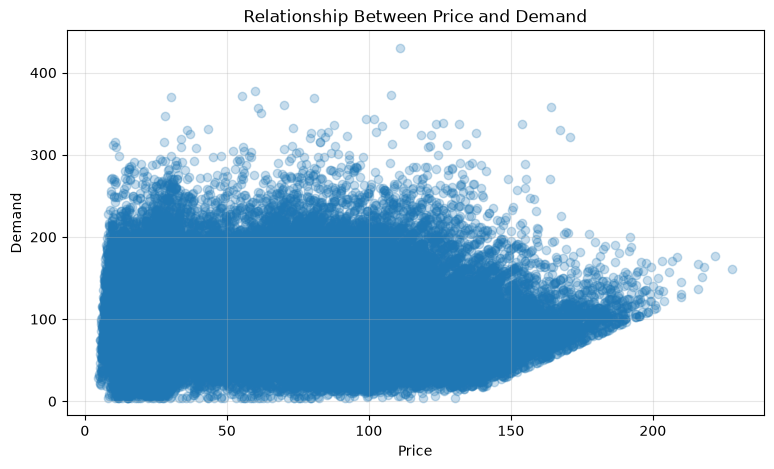

In [6]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

plt.scatter(
    df["Price"],
    df["Demand"],
    alpha=0.25
)

plt.xlabel("Price")
plt.ylabel("Demand")
plt.title("Relationship Between Price and Demand")
plt.grid(alpha=0.3)

plt.show()

In [7]:
# Explore unique business categories

print("Product Categories:")
print(df["Category"].value_counts())

print("\nRegions:")
print(df["Region"].value_counts())

print("\nNumber of unique stores:", df["Store ID"].nunique())
print("Number of unique products:", df["Product ID"].nunique())

Product Categories:
Category
Groceries      30400
Furniture      13680
Clothing       12160
Toys           10640
Electronics     9120
Name: count, dtype: int64

Regions:
Region
North    30400
South    15200
East     15200
West     15200
Name: count, dtype: int64

Number of unique stores: 5
Number of unique products: 20


In [8]:
# Calculate average demand by category

category_demand = (
    df.groupby("Category")["Demand"]
    .mean()
    .sort_values(ascending=False)
)

display(category_demand.round(2))

Category
Groceries      120.98
Clothing       112.62
Electronics     97.48
Toys            92.61
Furniture       73.58
Name: Demand, dtype: float64

In [9]:
# Calculate average price by category

category_price = (
    df.groupby("Category")["Price"]
    .mean()
    .sort_values(ascending=False)
)

display(category_price.round(2))

Category
Furniture      121.51
Electronics     83.17
Clothing        71.52
Groceries       51.66
Toys            26.91
Name: Price, dtype: float64

In [10]:
# Compare average price and demand by category

category_analysis = (
    df.groupby("Category")
    .agg(
        Average_Price=("Price", "mean"),
        Average_Demand=("Demand", "mean")
    )
    .round(2)
    .sort_values("Average_Demand", ascending=False)
)

display(category_analysis)

,Average_Price,Average_Demand
Category,,
Groceries,51.66,120.98
Clothing,71.52,112.62
Electronics,83.17,97.48
Toys,26.91,92.61
Furniture,121.51,73.58


In [11]:
# Calculate average demand by region

region_analysis = (
    df.groupby("Region")
    .agg(
        Average_Demand=("Demand", "mean"),
        Average_Price=("Price", "mean"),
        Total_Units_Sold=("Units Sold", "sum")
    )
    .round(2)
    .sort_values("Average_Demand", ascending=False)
)

display(region_analysis)

,Average_Demand,Average_Price,Total_Units_Sold
Region,,,
South,106.94,64.40,1386126
East,106.47,70.09,1375613
North,103.77,63.36,2680946
West,100.63,77.41,1308191


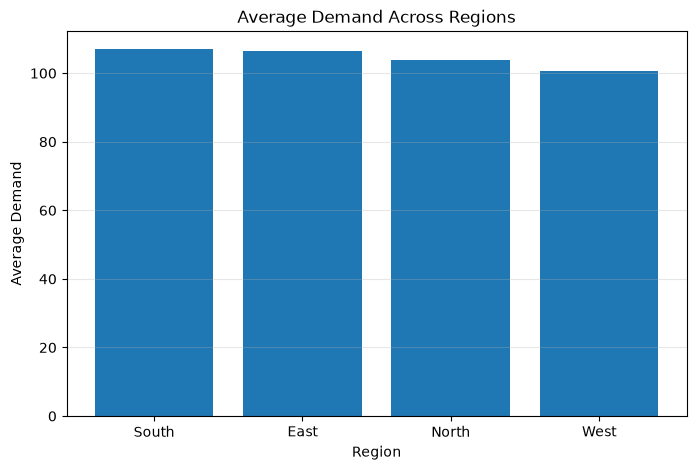

In [12]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.bar(
    region_analysis.index,
    region_analysis["Average_Demand"]
)

plt.xlabel("Region")
plt.ylabel("Average Demand")
plt.title("Average Demand Across Regions")

plt.grid(axis="y", alpha=0.3)
plt.show()

In [13]:
# Calculate average demand at each discount level

discount_analysis = (
    df.groupby("Discount")
    .agg(
        Average_Demand=("Demand", "mean"),
        Average_Price=("Price", "mean"),
        Number_of_Records=("Demand", "count")
    )
    .round(2)
    .sort_index()
)

display(discount_analysis)

,Average_Demand,Average_Price,Number_of_Records
Discount,,,
0,94.75,73.07,17126
5,94.94,68.53,16918
10,102.77,66.93,23298
15,123.58,67.08,6245
20,124.07,63.45,6191
25,122.97,58.74,6222


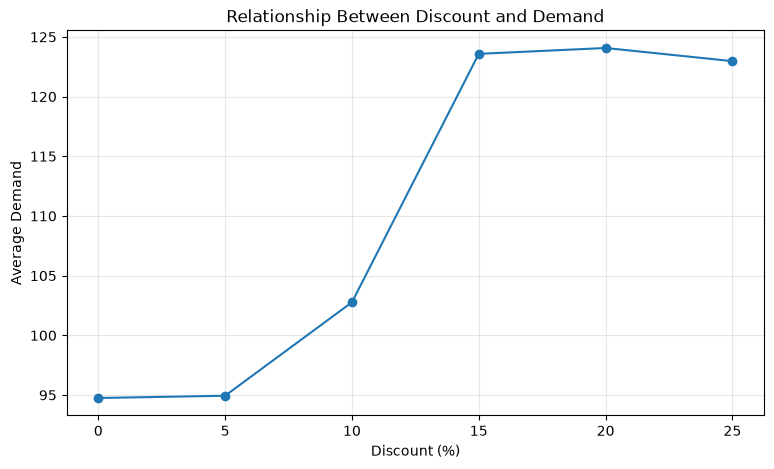

In [14]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

plt.plot(
    discount_analysis.index,
    discount_analysis["Average_Demand"],
    marker="o"
)

plt.xlabel("Discount (%)")
plt.ylabel("Average Demand")
plt.title("Relationship Between Discount and Demand")

plt.grid(alpha=0.3)
plt.show()

In [15]:
promotion_analysis = (
    df.groupby("Promotion")
    .agg(
        Average_Demand=("Demand", "mean"),
        Average_Price=("Price", "mean"),
        Average_Discount=("Discount", "mean"),
        Number_of_Records=("Demand", "count")
    )
    .round(2)
)

display(promotion_analysis)

,Average_Demand,Average_Price,Average_Discount,Number_of_Records
Promotion,,,,
0,95.03,68.92,4.98,51000
1,123.27,65.30,17.46,25000


In [16]:
pd.crosstab(
    df["Promotion"],
    df["Discount"],
    normalize="index"
).round(3) * 100

Discount,0,5,10,15,20,25
Promotion,,,,,,
0,33.6,33.2,33.2,0.0,0.0,0.0
1,0.0,0.0,25.4,25.0,24.8,24.9


In [17]:
inventory_analysis = (
    df.groupby("Inventory Level")
    .agg(
        Average_Demand=("Demand", "mean"),
        Average_Units_Sold=("Units Sold", "mean")
    )
    .round(2)
)

display(inventory_analysis.head(10))

,Average_Demand,Average_Units_Sold
Inventory Level,,
0,115.40,0.0
1,112.50,1.0
2,101.56,2.0
3,101.78,3.0
4,122.25,4.0
5,121.50,5.0
6,100.18,6.0
7,90.64,7.0
8,113.50,8.0


In [18]:
df["Inventory_Group"] = pd.cut(
    df["Inventory Level"],
    bins=[-1, 50, 100, 200, 400, float("inf")],
    labels=["0-50", "51-100", "101-200", "201-400", "400+"]
)

inventory_group_analysis = (
    df.groupby("Inventory_Group", observed=False)
    .agg(
        Average_Demand=("Demand", "mean"),
        Average_Units_Sold=("Units Sold", "mean"),
        Number_of_Records=("Demand", "count")
    )
    .round(2)
)

display(inventory_group_analysis)

,Average_Demand,Average_Units_Sold,Number_of_Records
Inventory_Group,,,
0-50,104.74,23.48,1620
51-100,92.79,63.81,7392
101-200,101.86,86.87,24674
201-400,103.70,93.17,22737
400+,112.46,101.11,19577


In [19]:
inventory_check = pd.DataFrame({
    "Metric": [
        "Units Sold greater than Inventory",
        "Units Sold equal to Inventory",
        "Inventory equal to zero"
    ],
    "Records": [
        (df["Units Sold"] > df["Inventory Level"]).sum(),
        (df["Units Sold"] == df["Inventory Level"]).sum(),
        (df["Inventory Level"] == 0).sum()
    ]
})

inventory_check["Percentage"] = (
    inventory_check["Records"] / len(df) * 100
).round(2)

display(inventory_check)

,Metric,Records,Percentage
0,Units Sold greater than Inventory,0,0.00
1,Units Sold equal to Inventory,8654,11.39
2,Inventory equal to zero,406,0.53


##  Final Exploratory Data Analysis (EDA) Summary

### 1. Dataset Overview
- Total observations: 76,000
- Total columns: 16
- Product categories: 5
- Regions: 4
- Stores: 5
- Unique products: 20

### 2. Data Quality
- No missing values were identified.
- No duplicate records were found.
- Data types were examined and understood.

### 3. Demand and Sales
- Average demand: 104.32 units.
- Average units sold: 88.83 units.
- Demand and units sold have a positive correlation of 0.833.
- Demand and actual sales are distinct measurements and should not be treated as interchangeable.

### 4. Product Category Analysis
- Groceries recorded the highest average demand (120.98).
- Furniture recorded the lowest average demand (73.58).
- Furniture had the highest average price (121.51).
- Toys had the lowest average price (26.91).

### 5. Regional Analysis
- South recorded the highest average demand (106.94).
- West recorded the lowest average demand (100.63).
- North recorded the highest total units sold, partly reflecting its larger number of observations.

### 6. Pricing, Discounts and Promotions
- Higher discount levels were generally associated with higher average demand.
- Average demand was 123.27 when promotions were active, compared with 95.03 without promotions.
- Promotions and discounts were closely connected in the dataset.
- These relationships are observational and do not establish causation.

### 7. Inventory Analysis
- Average units sold generally increased across higher inventory groups.
- The lowest inventory group (0–50) recorded average demand of 104.74 but average sales of only 23.48.
- 11.39% of observations had units sold equal to inventory.
- No observations had units sold greater than inventory.

### 8. Key Business Insights
1. Product categories differ considerably in their demand and pricing patterns.
2. Discount and promotion strategies are associated with changes in demand.
3. Inventory availability may constrain actual sales.
4. Demand, inventory and actual sales must be analyzed separately.
5. More detailed modeling is required to understand the relationships between pricing, promotions, inventory and demand.

### 9. Conclusion
The exploratory analysis provides an initial understanding of the dataset's structure, data quality and retail business patterns.

These findings establish a foundation for further business analysis, demand prediction and pricing and profitability modeling.

The next stage will investigate these relationships in greater detail before developing predictive and decision-making models.